# Validate chip-sales estimates against the published website data

The model notebooks and modules in this repo write per-chip and cumulative estimates to `csv_export/`, which feed the public dataset at [epoch.ai/data/ai-chip-sales](https://epoch.ai/data/ai-chip-sales). This notebook wraps `pipeline/validate.py`: it downloads the currently published dataset (in memory, nothing is written to disk), compares it cell by cell against the local CSVs for **every configured designer**, and reports where the two disagree.

Each compared cell is classified by its percent difference: **ok** (within 1%), **minor** (1–10%), or **major** (over 10%, worth investigating). The same checks run from the command line via `python -m pipeline.validate --designer all`, or as part of `python run_chip_model.py <family>`.

In [1]:
# Colab only opens this notebook file, so fetch the rest of the repo and install squigglepy.
# Locally, it only moves to the repo root so the imports and file paths resolve.
import os, sys
if "google.colab" in sys.modules:
    !pip install -q squigglepy
    if not os.path.exists("ai-chip-counts"):
        !git clone -q --depth 1 https://github.com/epoch-research/ai-chip-counts.git
    %cd ai-chip-counts
elif os.path.basename(os.getcwd()) == "notebooks":
    # Jupyter starts in notebooks/, but every path here is relative to the repo root.
    os.chdir("..")
if os.getcwd() not in sys.path:
    sys.path.insert(0, os.getcwd())

In [2]:
import pandas as pd
from IPython.display import display, Markdown

from pipeline.validate import (
    DESIGNER_CONFIGS,
    fetch_website_tables,
    validate_designer,
    verdict,
    coverage_summary,
    metric_summary,
    pct_diff_table,
    plot_cumulative_timeseries,
)

web_tables = fetch_website_tables()
all_results = {designer: validate_designer(designer, web_tables) for designer in DESIGNER_CONFIGS}

pd.DataFrame([{"designer": designer, **verdict(results)} for designer, results in all_results.items()])

Loaded 3 published tables (27,459 bytes)


,designer,major_cells,unmatched_rows,ok
0,nvidia,30,15,False
1,google,2,0,False
2,amd,0,0,True
3,amazon,0,0,True


## Row coverage and run timestamps

Do the two sides contain the same rows, and do they come from the same model run? If `same run` is False, the published table was generated from a different (usually older) run, so value differences below are expected rather than alarming.

In [3]:
frames = []
for designer, results in all_results.items():
    df = coverage_summary(results)
    df.insert(0, "designer", designer)
    frames.append(df)
pd.concat(frames, ignore_index=True)

,designer,table,rows matched,local only,website only,local run,website run,same run
0,nvidia,Quarterly timelines by chip,54,5,0,11-18-2026 14:58 (x59),08-27-2026 15:06 (x54),False
1,nvidia,Cumulative timelines by chip,92,9,0,11-18-2026 14:58 (x101),08-27-2026 15:06 (x92),False
2,nvidia,Cumulative totals by designer,19,1,0,11-18-2026 14:58 (x20),08-27-2026 15:06 (x19),False
3,google,Quarterly timelines by chip,38,0,0,11-05-2026 11:51 (x38),09-30-2026 14:07 (x38),False
4,google,Cumulative timelines by chip,73,0,0,11-05-2026 11:51 (x73),09-30-2026 14:07 (x73),False
5,google,Cumulative totals by designer,16,0,0,11-05-2026 11:51 (x16),09-30-2026 14:07 (x16),False
6,amd,Quarterly timelines by chip,35,0,0,08-28-2026 11:47 (x35),08-27-2026 16:14 (x35),False
7,amd,Cumulative timelines by chip,48,0,0,08-28-2026 11:47 (x48),08-27-2026 16:14 (x48),False
8,amd,Cumulative totals by designer,10,0,0,08-28-2026 11:47 (x10),08-27-2026 16:14 (x10),False
9,amazon,Quarterly timelines by chip,15,0,0,10-14-2026 14:34 (x15),10-14-2026 14:34 (x15),True


## Per-metric summary

How well each metric agrees, per designer and table: counts of ok/minor/major cells, the average signed difference (a consistent positive or negative bias means the local model has shifted in one direction), and the typical and worst absolute differences.

In [4]:
frames = []
for designer, results in all_results.items():
    df = metric_summary(results)
    df.insert(0, "designer", designer)
    frames.append(df)
pd.concat(frames, ignore_index=True).round(2)

,designer,table,metric,n,ok,minor,major,mean_signed_pct,mean_abs_pct,max_abs_pct
0,nvidia,Quarterly timelines by chip,Units median,54,51,0,3,23.38,23.41,859.83
1,nvidia,Quarterly timelines by chip,Units p5,54,51,0,3,23.55,23.59,862.77
2,nvidia,Quarterly timelines by chip,Units p95,54,51,0,3,23.46,23.51,861.25
3,nvidia,Quarterly timelines by chip,H100e median,54,51,0,3,23.38,23.41,859.83
4,nvidia,Quarterly timelines by chip,H100e p5,54,51,0,3,23.55,23.59,862.77
...,...,...,...,...,...,...,...,...,...,...
85,amazon,Cumulative totals by designer,H100e p5,10,10,0,0,0.00,0.00,0.00
86,amazon,Cumulative totals by designer,H100e p95,10,10,0,0,0.00,0.00,0.00
87,amazon,Cumulative totals by designer,Power MW median,10,10,0,0,0.00,0.00,0.00
88,amazon,Cumulative totals by designer,Power MW p5,10,10,0,0,0.00,0.00,0.00


## Percent differences by quarter

Where the differences actually are — by chip for the two chip-level comparisons, and by metric for the designer totals. For the cumulative tables, a column means the total *through* that quarter.

How to read a cell:

- a **number** is the percent difference (local vs website)
- `-` means neither dataset has that cell (e.g. quarters before a chip launched)
- `local only` / `website only` flag rows that exist on just one side — these also show up in the coverage counts above
- `no data` means the row matched but the value is blank on one side

When every cell in a table is within tolerance and nothing is one-sided, a confirmation line is printed instead of leaving you to scan the grid.

In [5]:
for designer, results in all_results.items():
    display(Markdown(f"### {designer}"))
    display(Markdown("**Quarterly timelines — median units per chip and quarter**"))
    display(pct_diff_table(results, "timelines_by_chip"))
    display(Markdown("**Cumulative by chip — median units per chip, through each quarter**"))
    display(pct_diff_table(results, "cumulative_by_chip"))
    display(Markdown("**Designer totals — every metric, through each quarter**"))
    display(pct_diff_table(results, "cumulative_by_designer", metric=None))

### nvidia

**Quarterly timelines — median units per chip and quarter**

quarter,Q1 2022,Q2 2022,Q3 2022,Q4 2022,Q1 2023,Q2 2023,Q3 2023,Q4 2023,Q1 2024,Q2 2024,Q3 2024,Q4 2024,Q1 2025,Q2 2025,Q3 2025,Q4 2025,Q1 2026,Q2 2026,Q3 2026,Q4 2026
chip,,,,,,,,,,,,,,,,,,,,
A100,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,-,-,-,-,-,-,-,-,-,-,-,-
A800,-,-,-,-0.1,-0.1,-0.1,-0.1,-0.1,-,-,-,-,-,-,-,-,-,-,-,-
B200,-,-,-,-,-,-,-,-,-,-,-,0.1,0.1,0.1,0.1,0.1,0.1,0.1,153.7,local only
B300,-,-,-,-,-,-,-,-,-,-,-,-,-,0.0,0.0,0.0,0.0,0.0,248.4,local only
H100,-,-,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,-,0.0,859.8,local only
H20,-,-,-,-,-,-,-,-,0.0,0.0,0.0,0.0,0.0,0.0,0.0,-,-,-,-,-
H800,-,-,-,-,0.1,0.1,0.1,0.1,-,-,-,-,-,-,-,-,-,-,-,-
R200,-,-,-,-,-,-,-,-,-,-,-,-,-,-,-,-,-,-,local only,local only


**Cumulative by chip — median units per chip, through each quarter**

quarter,Q1 2022,Q2 2022,Q3 2022,Q4 2022,Q1 2023,Q2 2023,Q3 2023,Q4 2023,Q1 2024,Q2 2024,Q3 2024,Q4 2024,Q1 2025,Q2 2025,Q3 2025,Q4 2025,Q1 2026,Q2 2026,Q3 2026,Q4 2026
chip,,,,,,,,,,,,,,,,,,,,
A100,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,local only
A800,-,-,-,-0.1,-0.1,-0.1,-0.1,-0.1,-0.1,-0.1,-0.1,-0.1,-0.1,-0.1,-0.1,-0.1,-0.1,-0.1,-0.1,local only
B200,-,-,-,-,-,-,-,-,-,-,-,0.1,0.1,0.1,0.1,0.1,0.1,0.1,3.3,local only
B300,-,-,-,-,-,-,-,-,-,-,-,-,-,0.0,0.0,0.0,0.0,0.0,24.0,local only
H100,-,-,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.6,local only
H20,-,-,-,-,-,-,-,-,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,local only
H800,-,-,-,-,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,local only
R200,-,-,-,-,-,-,-,-,-,-,-,-,-,-,-,-,-,-,local only,local only


**Designer totals — every metric, through each quarter**

... (24 outputs left out)

quarter,Q1 2024,Q2 2024,Q3 2024,Q4 2024,Q1 2025,Q2 2025,Q3 2025,Q4 2025,Q1 2026,Q2 2026
chip,,,,,,,,,,
Trainium1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Trainium2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Trainium3,-,-,-,-,-,-,-,-,-,0.0


**Designer totals — every metric, through each quarter**

Cumulative totals by designer: all 90 cells match within the 1.0% tolerance; no one-sided rows


quarter,Q1 2024,Q2 2024,Q3 2024,Q4 2024,Q1 2025,Q2 2025,Q3 2025,Q4 2025,Q1 2026,Q2 2026
metric,,,,,,,,,,
Units median,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Units p5,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Units p95,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
H100e median,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
H100e p5,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
H100e p95,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Power MW median,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Power MW p5,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Power MW p95,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


## Cumulative totals over time

Local vs published cumulative totals per designer. The published values are drawn as a wide orange line underneath the local blue line, so where the two agree the orange shows as a halo around the blue; the shaded band is the local 5th–95th percentile range.

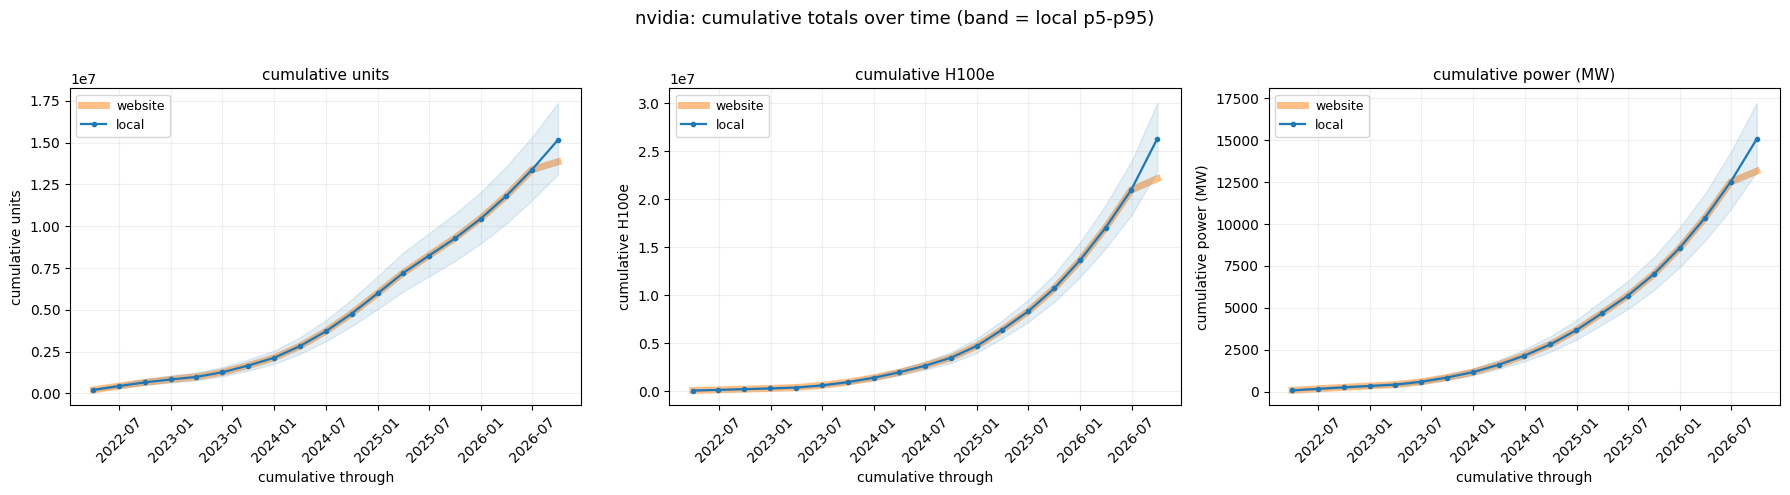

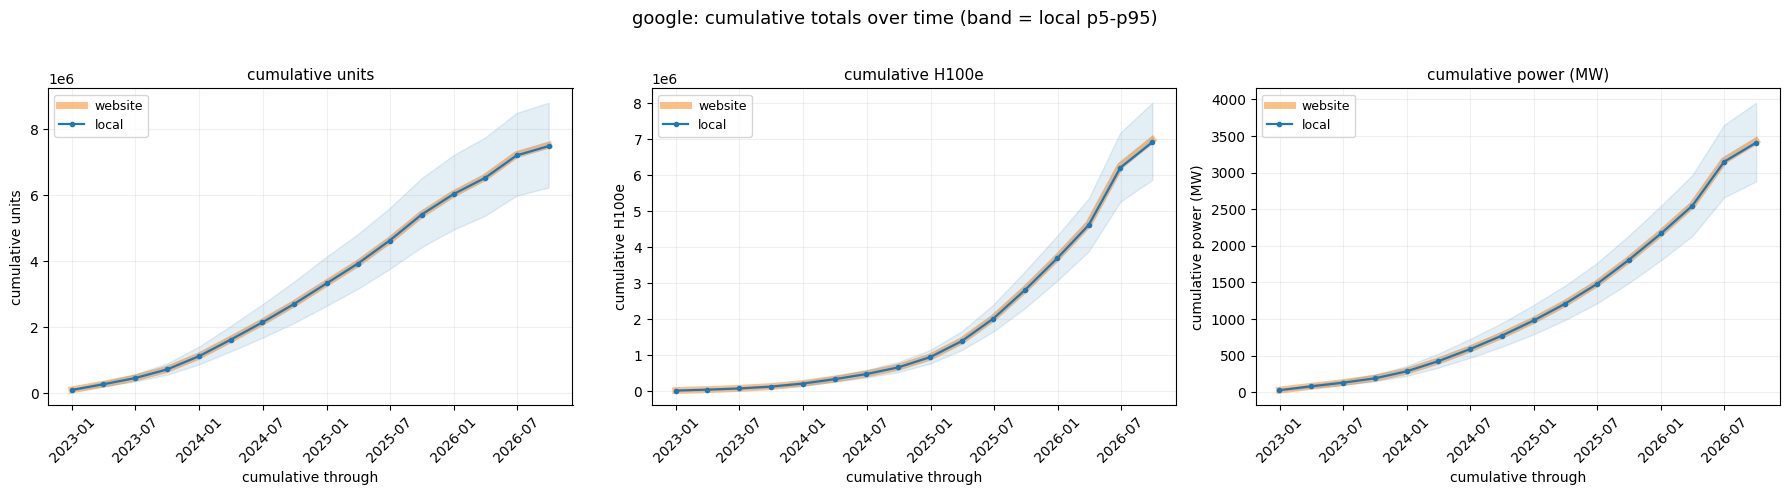

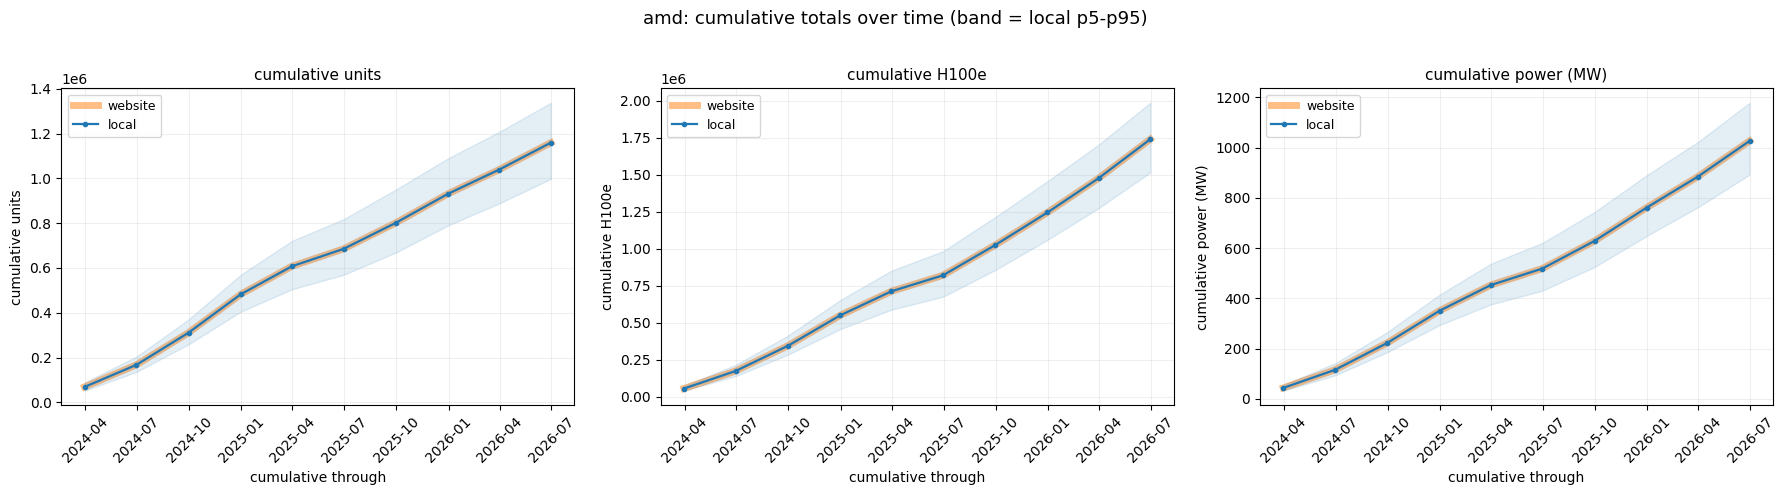

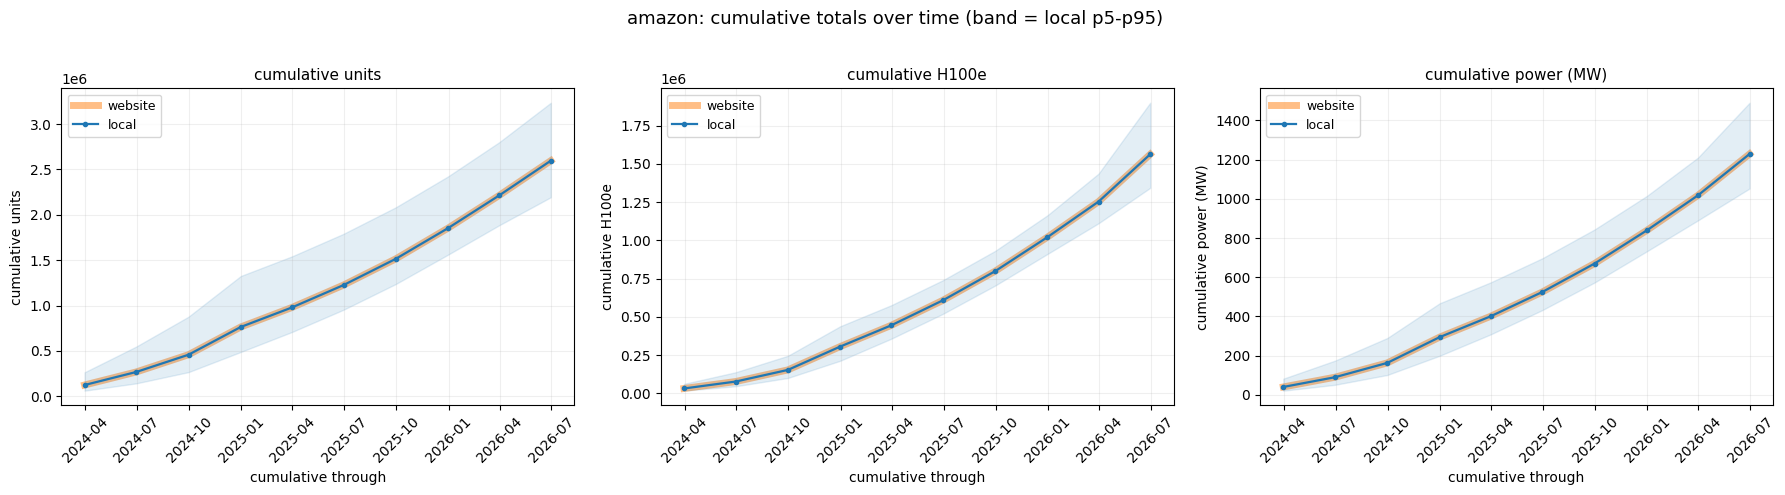

In [6]:
for designer, results in all_results.items():
    fig = plot_cumulative_timeseries(results, designer)
    if fig is None:
        print(f"{designer}: no matched designer-totals rows to plot (see row coverage above)")